# BERT: тональность IMDB и категории новостей
Один пайплайн для двух датасетов: загрузка → векторизация текста (WordPiece-токенизатор BERT) → дообучение `BertForSequenceClassification` → оценка и предсказания.

In [1]:
import numpy as np, pandas as pd, torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
from torch.utils.data import TensorDataset, DataLoader
from transformers import BertTokenizerFast, BertForSequenceClassification

MODEL = 'bert-base-uncased'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
tokenizer = BertTokenizerFast.from_pretrained(MODEL)
torch.manual_seed(42)

## Данные
IMDB: `review` → `positive/negative`. News: `headline + short_description` → `category` (берём 10 самых частых категорий). Для скорости используем подвыборку.

In [2]:
imdb = pd.read_csv('IMDB Dataset (2).csv').sample(6000, random_state=42)
imdb['text'] = imdb['review'].str.replace('<br />', ' ', regex=False)
imdb['label'] = imdb['sentiment']

news = pd.read_json('News_Category_Dataset_v3.json', lines=True)
top = news['category'].value_counts().index[:10]
news = news[news['category'].isin(top)].sample(10000, random_state=42)
news['text'] = news['headline'] + '. ' + news['short_description']
news['label'] = news['category']

imdb[['text', 'label']].head(), news[['text', 'label']].head()

(                                                    text     label
 33553  I really liked this Summerslam due to the look...  positive
 9427   Not many television shows appeal to quite as m...  positive
 199    The film quickly gets to a major chase scene w...  negative
 12447  Jane Austen would definitely approve of this o...  positive
 39489  Expectations were somewhat high for me when I ...  negative,
                                                      text           label
 1070    Kamala Harris To Travel To Poland And Romania ...        POLITICS
 38212   Katy Perry Has The Best Response To Ryan Phill...   ENTERTAINMENT
 135727  Mushroom Barley Soup. Making this main-course-...    FOOD & DRINK
 120417  My Wakeup Call From Arianna Huffington. I don'...  HEALTHY LIVING
 207916  Weekly Roundup of eBay Vintage Clothing Finds ...  STYLE & BEAUTY)

## Векторизация текста
Токенизатор BERT (WordPiece) разбивает текст на подслова и превращает их в векторы индексов `input_ids` + `attention_mask`.

In [3]:
def vectorize(texts, max_len):
    enc = tokenizer(list(texts), truncation=True, padding='max_length', max_length=max_len, return_tensors='pt')
    return enc['input_ids'], enc['attention_mask']

ids, mask = vectorize(['This movie was great!'], 16)
print(tokenizer.convert_ids_to_tokens(ids[0]))
print(ids[0])
print(mask[0])

['[CLS]', 'this', 'movie', 'was', 'great', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
tensor([ 101, 2023, 3185, 2001, 2307,  999,  102,    0,    0,    0,    0,    0,
           0,    0,    0,    0])
tensor([1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0])


## Обучение и оценка

In [4]:
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import (precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score,
                             log_loss, matthews_corrcoef, cohen_kappa_score, top_k_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def evaluate(model, dl):
    model.eval(); losses, probs = [], []
    with torch.no_grad():
        for ids, mask, lab in dl:
            out = model(ids.to(device), attention_mask=mask.to(device), labels=lab.to(device))
            losses.append(out.loss.item()); probs.append(out.logits.softmax(1).cpu())
    return np.mean(losses), torch.cat(probs).numpy()

def run_bert(df, max_len, epochs=2, batch=16):
    le = LabelEncoder()
    y = le.fit_transform(df['label'])
    X_tr, X_te, y_tr, y_te = train_test_split(df['text'], y, test_size=0.2, stratify=y, random_state=42)

    # dtype=torch.long: CrossEntropyLoss требует int64 (на Windows numpy отдаёт int32)
    make_dl = lambda X, y, sh: DataLoader(TensorDataset(*vectorize(X, max_len), torch.tensor(y, dtype=torch.long)),
                                          batch_size=batch, shuffle=sh)
    train_dl, test_dl = make_dl(X_tr, y_tr, True), make_dl(X_te, y_te, False)

    model = BertForSequenceClassification.from_pretrained(MODEL, num_labels=len(le.classes_)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-5)

    hist = []
    for ep in range(epochs):
        model.train(); losses = []
        for ids, mask, lab in tqdm(train_dl, desc=f'epoch {ep + 1}/{epochs} [{device}]'):
            loss = model(ids.to(device), attention_mask=mask.to(device), labels=lab.to(device)).loss
            opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        val_loss, proba = evaluate(model, test_dl)
        pred = proba.argmax(1)
        hist.append({'epoch': ep + 1, 'train_loss': np.mean(losses), 'val_loss': val_loss,
                     'val_acc': accuracy_score(y_te, pred), 'val_f1_macro': f1_score(y_te, pred, average='macro')})
        print({k: round(float(v), 4) for k, v in hist[-1].items()})

    return dict(model=model, le=le, max_len=max_len, X_tr=X_tr, y_tr=y_tr, X_te=X_te, y_te=y_te,
                proba=proba, hist=pd.DataFrame(hist))

def predict(r, texts):
    ids, mask = vectorize(texts, r['max_len'])
    r['model'].eval()
    with torch.no_grad():
        proba = r['model'](ids.to(device), attention_mask=mask.to(device)).logits.softmax(1).cpu().numpy()
    return pd.DataFrame({'text': texts, 'pred': r['le'].inverse_transform(proba.argmax(1)),
                         'confidence': proba.max(1).round(3)})

## Метрики
- **accuracy / balanced accuracy** — доля верных ответов (balanced — среднее recall по классам, устойчива к дисбалансу)
- **precision / recall / F1 (macro, weighted)** — точность и полнота по классам
- **ROC-AUC** — качество вероятностей (для news — one-vs-rest)
- **log loss** — насколько хорошо откалиброваны вероятности
- **MCC, Cohen's kappa** — согласие с разметкой с поправкой на случайность
- **top-3 accuracy** (news) — верная категория среди трёх самых вероятных

Для сравнения строится бейзлайн TF-IDF + логистическая регрессия. Графики: loss и качество по эпохам, матрица ошибок, ROC-кривая / F1 по классам, распределение уверенности модели и самые уверенные ошибки.

In [5]:
def metrics(y, proba):
    pred, binary = proba.argmax(1), proba.shape[1] == 2
    m = {'accuracy': accuracy_score(y, pred),
         'balanced_accuracy': balanced_accuracy_score(y, pred),
         'precision_macro': precision_score(y, pred, average='macro'),
         'recall_macro': recall_score(y, pred, average='macro'),
         'f1_macro': f1_score(y, pred, average='macro'),
         'f1_weighted': f1_score(y, pred, average='weighted'),
         'roc_auc': roc_auc_score(y, proba[:, 1]) if binary else roc_auc_score(y, proba, multi_class='ovr'),
         'log_loss': log_loss(y, proba),
         'mcc': matthews_corrcoef(y, pred),
         'cohen_kappa': cohen_kappa_score(y, pred)}
    if not binary:
        m['top3_accuracy'] = top_k_accuracy_score(y, proba, k=3)
    return m

def tfidf_baseline(r):
    # бейзлайн для сравнения: TF-IDF векторы слов + логистическая регрессия
    vec = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), sublinear_tf=True)
    clf = LogisticRegression(max_iter=1000).fit(vec.fit_transform(r['X_tr']), r['y_tr'])
    return clf.predict_proba(vec.transform(r['X_te']))

def report(r, name):
    le, y, proba = r['le'], r['y_te'], r['proba']
    pred, binary = proba.argmax(1), proba.shape[1] == 2

    table = pd.DataFrame({'BERT': metrics(y, proba), 'TF-IDF + LogReg': metrics(y, tfidf_baseline(r))}).T.round(4)
    print(f'===== {name}: метрики на тесте ({len(y)} объектов) =====')
    display(table)
    print(classification_report(y, pred, target_names=le.classes_, digits=4))

    fig, ax = plt.subplots(1, 4, figsize=(24, 5.5))
    r['hist'].plot(x='epoch', y=['train_loss', 'val_loss'], marker='o', ax=ax[0], title='Loss по эпохам')
    r['hist'].plot(x='epoch', y=['val_acc', 'val_f1_macro'], marker='o', ax=ax[1], title='Качество на валидации')
    ConfusionMatrixDisplay(confusion_matrix(y, pred, normalize='true'), display_labels=le.classes_).plot(
        ax=ax[2], cmap='Blues', values_format='.2f', colorbar=False, xticks_rotation=60)
    ax[2].set_title('Нормированная матрица ошибок')
    if binary:
        RocCurveDisplay.from_predictions(y, proba[:, 1], ax=ax[3], name='BERT')
        ax[3].set_title('ROC-кривая')
    else:
        pd.Series(f1_score(y, pred, average=None), le.classes_).sort_values().plot.barh(ax=ax[3], title='F1 по классам')
    plt.suptitle(name); plt.tight_layout(); plt.show()

    conf = proba.max(1)
    plt.figure(figsize=(7, 3.5))
    plt.hist([conf[pred == y], conf[pred != y]], bins=20, label=['верно', 'ошибка'], stacked=True)
    plt.title(f'{name}: уверенность модели'); plt.xlabel('max вероятность'); plt.legend(); plt.show()

    err = pd.DataFrame({'text': r['X_te'].str[:150].values, 'true': le.inverse_transform(y),
                        'pred': le.inverse_transform(pred), 'confidence': conf.round(3)})
    print('Самые уверенные ошибки:')
    display(err[err['true'] != err['pred']].nlargest(5, 'confidence'))
    return table.loc['BERT']

## 1. IMDB — положительный / отрицательный отзыв

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/2 [cuda]:   0%|          | 0/300 [00:00<?, ?it/s]

{'epoch': 1.0, 'train_loss': 0.3491, 'val_loss': 0.2624, 'val_acc': 0.8867, 'val_f1_macro': 0.8863}


epoch 2/2 [cuda]:   0%|          | 0/300 [00:00<?, ?it/s]

{'epoch': 2.0, 'train_loss': 0.1673, 'val_loss': 0.314, 'val_acc': 0.8958, 'val_f1_macro': 0.8957}
===== IMDB: метрики на тесте (1200 объектов) =====


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc,log_loss,mcc,cohen_kappa
BERT,0.8958,0.8955,0.8972,0.8955,0.8957,0.8957,0.9632,0.3140,0.7927,0.7915
TF-IDF + LogReg,0.8750,0.8749,0.8753,0.8749,0.8749,0.8750,0.9475,0.4261,0.7501,0.7499


              precision    recall  f1-score   support

    negative     0.9180    0.8670    0.8918       594
    positive     0.8764    0.9241    0.8996       606

    accuracy                         0.8958      1200
   macro avg     0.8972    0.8955    0.8957      1200
weighted avg     0.8970    0.8958    0.8957      1200



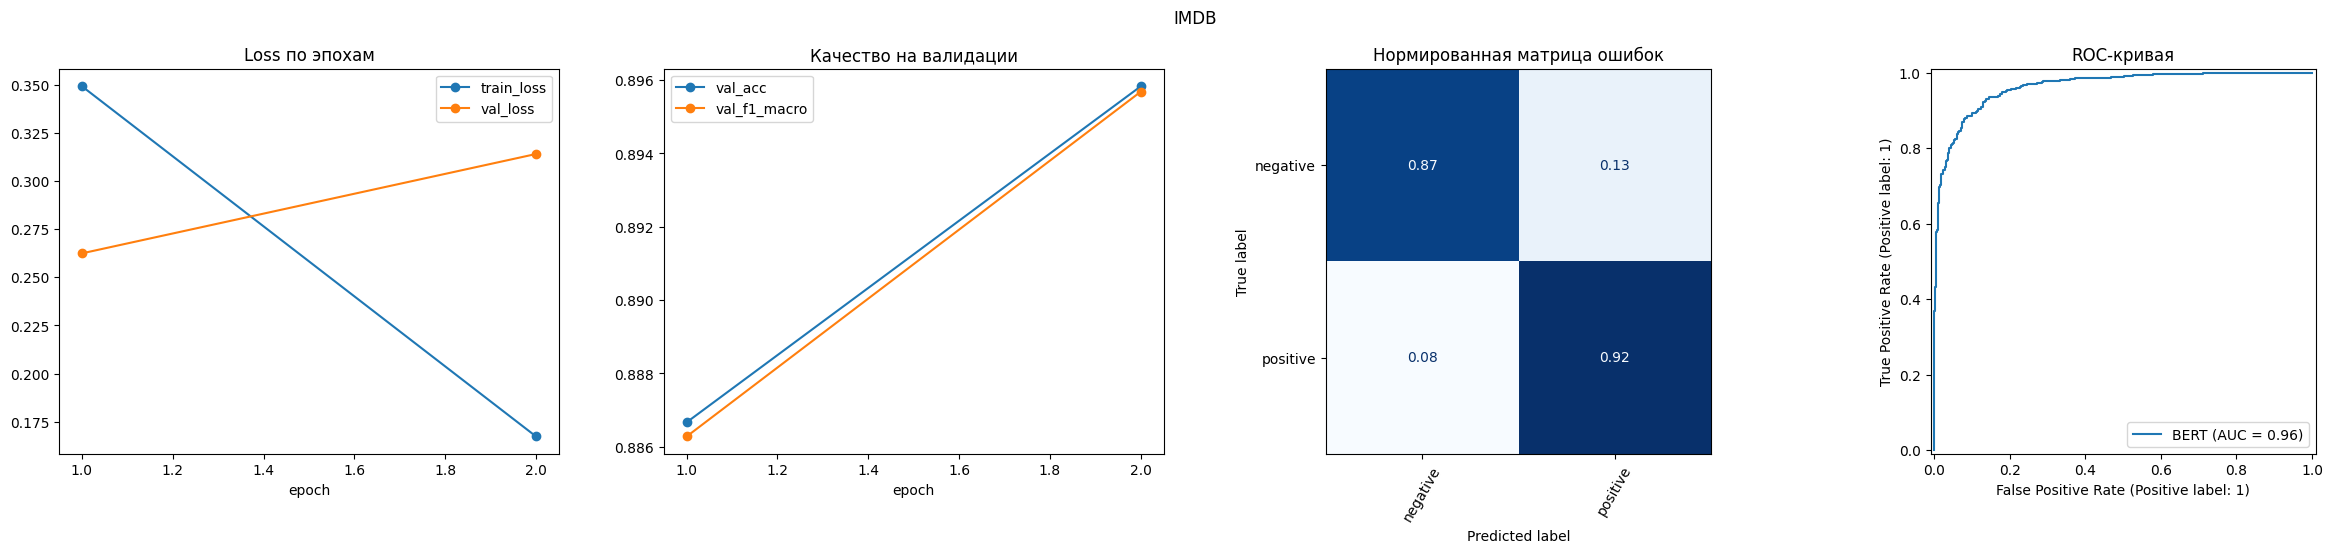

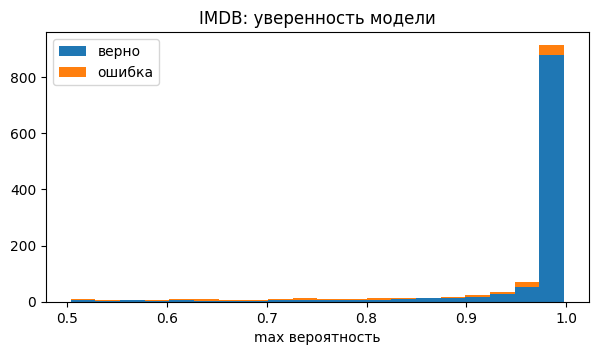

Самые уверенные ошибки:


,text,true,pred,confidence
250,wow! i watched the trailer for this one and th...,negative,positive,0.996
380,I first watched Kindred in 1987 along with ano...,negative,positive,0.996
1198,Most yeti pictures are fatally undermined by a...,positive,negative,0.996
749,Being a fan of time travel stories I was surpr...,positive,negative,0.995
768,This cheapo remake of the terrific Five Star F...,positive,negative,0.995


,text,pred,confidence
0,"An absolute masterpiece, I loved every minute.",positive,0.993
1,"Boring plot and terrible acting, a waste of time.",negative,0.996


In [6]:
imdb_bert = run_bert(imdb, max_len=256)
imdb_m = report(imdb_bert, 'IMDB')
predict(imdb_bert, ['An absolute masterpiece, I loved every minute.',
                    'Boring plot and terrible acting, a waste of time.'])

## 2. News Category — категория новости

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1/2 [cuda]:   0%|          | 0/500 [00:00<?, ?it/s]

{'epoch': 1.0, 'train_loss': 1.035, 'val_loss': 0.6237, 'val_acc': 0.8155, 'val_f1_macro': 0.7471}


epoch 2/2 [cuda]:   0%|          | 0/500 [00:00<?, ?it/s]

{'epoch': 2.0, 'train_loss': 0.4804, 'val_loss': 0.5581, 'val_acc': 0.828, 'val_f1_macro': 0.7762}
===== News Category: метрики на тесте (2000 объектов) =====


,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc,log_loss,mcc,cohen_kappa,top3_accuracy
BERT,0.8280,0.7641,0.8037,0.7641,0.7762,0.8234,0.9724,0.5581,0.7983,0.7971,0.9655
TF-IDF + LogReg,0.6905,0.5352,0.7824,0.5352,0.5618,0.6534,0.9372,1.1993,0.6332,0.6215,0.8815


                precision    recall  f1-score   support

      BUSINESS     0.7000    0.5326    0.6049        92
 ENTERTAINMENT     0.8255    0.9431    0.8804       281
  FOOD & DRINK     0.8283    0.7961    0.8119       103
HEALTHY LIVING     0.5833    0.3717    0.4541       113
     PARENTING     0.7543    0.8919    0.8173       148
      POLITICS     0.9283    0.9024    0.9152       574
  QUEER VOICES     0.8889    0.6337    0.7399       101
STYLE & BEAUTY     0.9407    0.8639    0.9007       147
        TRAVEL     0.8889    0.8447    0.8662       161
      WELLNESS     0.6986    0.8607    0.7712       280

      accuracy                         0.8280      2000
     macro avg     0.8037    0.7641    0.7762      2000
  weighted avg     0.8294    0.8280    0.8234      2000



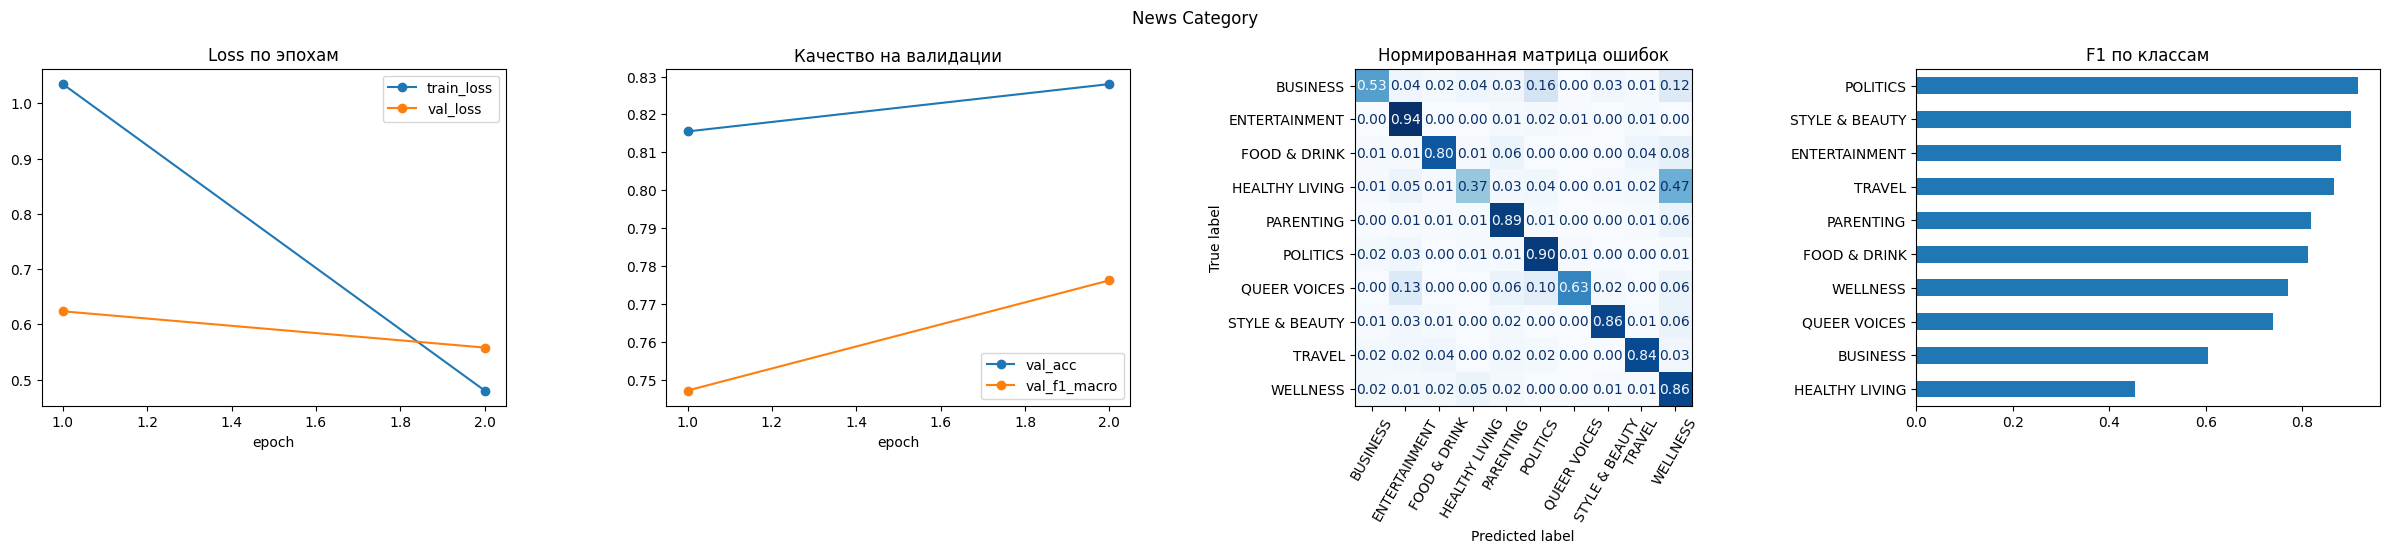

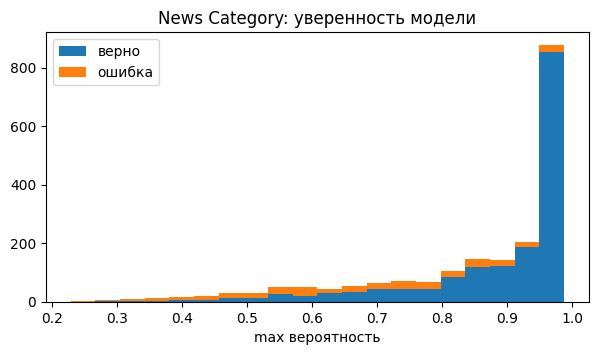

Самые уверенные ошибки:


,text,true,pred,confidence
864,Five Cyber Security Takeaways From the Mid-Ter...,BUSINESS,POLITICS,0.982
1214,Paul Krugman: Paul Ryan's Budget Plan Is 'A Fr...,BUSINESS,POLITICS,0.982
1102,College Mouth. My daughter is about to graduat...,BUSINESS,PARENTING,0.978
273,6 Signs Your Child Might Have Dyslexia. This p...,HEALTHY LIVING,PARENTING,0.977
1105,After Dark: World Of Wonder's Randy Barbato & ...,QUEER VOICES,ENTERTAINMENT,0.974


,text,pred,confidence
0,Lakers beat Celtics in overtime thriller,POLITICS,0.621
1,Senate passes new bill on healthcare reform,POLITICS,0.968
2,Easy pasta recipe for busy weeknights,FOOD & DRINK,0.932


In [7]:
news_bert = run_bert(news, max_len=64)
news_m = report(news_bert, 'News Category')
predict(news_bert, ['Lakers beat Celtics in overtime thriller',
                    'Senate passes new bill on healthcare reform',
                    'Easy pasta recipe for busy weeknights'])

## Итоговое сравнение BERT на двух датасетах

In [8]:
pd.DataFrame({'IMDB': imdb_m, 'News Category': news_m}).round(4)

,IMDB,News Category
accuracy,0.8958,0.8280
balanced_accuracy,0.8955,0.7641
cohen_kappa,0.7915,0.7971
f1_macro,0.8957,0.7762
f1_weighted,0.8957,0.8234
log_loss,0.3140,0.5581
mcc,0.7927,0.7983
precision_macro,0.8972,0.8037
recall_macro,0.8955,0.7641
roc_auc,0.9632,0.9724
